In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/Raj/Desktop/DA final project/car_sales_2000_rows.csv")

In [3]:
df.head()

,Sale_ID,Sale_Date,Brand,Model,Year,Selling_Price,Fuel_Type,Transmission,Mileage,Mileage_Unit,Region,Color
0,S01073,2025-04-18,Hyundai,Creta,2025,1254000,Diesel,Automatic,18.7,km/l,West,Black
1,S01049,2025-04-15,Honda,Amaze,2025,719000,Petrol,Manual,20.2,km/l,North,Silver
2,S00205,2025-03-23,Maruti,Brezza,2025,879000,Petrol,Manual,20.8,km/l,West,White
3,S00695,2026-09-24,Volkswagen,Taigun,2024,1568000,Petrol,Automatic,16.3,km/l,South,Blue
4,S01759,2025-09-19,Mahindra,Scorpio,2023,1446000,Diesel,Manual,16.9,km/l,North,Grey


In [4]:
df.tail()

,Sale_ID,Sale_Date,Brand,Model,Year,Selling_Price,Fuel_Type,Transmission,Mileage,Mileage_Unit,Region,Color
1995,S01604,2025-02-16,Maruti,Dzire,2024,685000,CNG,Manual,32.7,km/l,North,Grey
1996,S00503,2024-09-10,Kia,Carens,2020,1334000,Diesel,Automatic,19.0,km/l,East,Grey
1997,S00538,2024-12-09,Kia,Seltos,2025,1317000,Petrol,Automatic,16.4,km/l,West,Black
1998,S01221,2024-10-08,Tata,Tiago EV,2021,803000,Electric,Automatic,294.0,km/charge,West,White
1999,S00176,2026-03-31,Hyundai,Creta,2025,1477000,Diesel,Automatic,19.7,km/l,South,White


In [6]:
df.shape

(2000, 12)

In [8]:
#check column
df.columns

Index(['Sale_ID', 'Sale_Date', 'Brand', 'Model', 'Year', 'Selling_Price',
       'Fuel_Type', 'Transmission', 'Mileage', 'Mileage_Unit', 'Region',
       'Color'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sale_ID        2000 non-null   object 
 1   Sale_Date      2000 non-null   object 
 2   Brand          2000 non-null   object 
 3   Model          2000 non-null   object 
 4   Year           2000 non-null   int64  
 5   Selling_Price  2000 non-null   int64  
 6   Fuel_Type      2000 non-null   object 
 7   Transmission   2000 non-null   object 
 8   Mileage        1982 non-null   float64
 9   Mileage_Unit   2000 non-null   object 
 10  Region         1988 non-null   object 
 11  Color          1985 non-null   object 
dtypes: float64(1), int64(2), object(9)
memory usage: 187.6+ KB


In [10]:
# stastic info
df.describe()

,Year,Selling_Price,Mileage
count,2000.000000,2.000000e+03,1982.000000
mean,2023.265000,1.119091e+06,28.857619
std,1.929673,5.052201e+05,51.619025
min,2019.000000,2.980000e+05,11.500000
25%,2022.000000,7.460000e+05,17.025000
50%,2024.000000,1.031500e+06,19.000000
75%,2025.000000,1.413250e+06,21.500000
max,2026.000000,4.031000e+06,351.400000


In [11]:
df.isnull().sum()

Sale_ID           0
Sale_Date         0
Brand             0
Model             0
Year              0
Selling_Price     0
Fuel_Type         0
Transmission      0
Mileage          18
Mileage_Unit      0
Region           12
Color            15
dtype: int64

In [12]:
df.nunique()

Sale_ID          1980
Sale_Date         869
Brand              10
Model              32
Year                8
Selling_Price    1124
Fuel_Type           5
Transmission        2
Mileage           260
Mileage_Unit        2
Region              4
Color               6
dtype: int64

In [13]:
categorical_columns = ['Brand', 'Fuel_Type', 'Transmission', 'Region', 'Color', 'Mileage_Unit']

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Brand:
['Hyundai' 'Honda' 'Maruti' 'Volkswagen' 'Mahindra' 'Toyota' 'Skoda'
 'Tata' 'Renault' 'Kia']

Fuel_Type:
['Diesel' 'Petrol' 'Hybrid' 'Electric' 'CNG']

Transmission:
['Automatic' 'Manual']

Region:
['West' 'North' 'South' 'East' nan]

Color:
['Black' 'Silver' 'White' 'Blue' 'Grey' 'Red' nan]

Mileage_Unit:
['km/l' 'km/charge']


In [15]:
df.duplicated().sum()

np.int64(18)

In [16]:
df['Sale_ID'].duplicated().sum()

np.int64(20)

In [17]:
# Investigate Duplicate Sale_IDs

duplicate_ids = df[df['Sale_ID'].duplicated(keep=False)]

duplicate_ids.sort_values('Sale_ID')

,Sale_ID,Sale_Date,Brand,Model,Year,Selling_Price,Fuel_Type,Transmission,Mileage,Mileage_Unit,Region,Color
964,S00057,2026-04-07,Mahindra,Thar,2022,1214000,Petrol,Automatic,13.6,km/l,West,White
924,S00057,2026-04-07,Mahindra,Thar,2022,1214000,Petrol,Automatic,13.6,km/l,West,White
1720,S00070,2026-10-17,Mahindra,Bolero,2023,790000,Diesel,Manual,17.7,km/l,East,Red
556,S00070,2026-10-17,Mahindra,Bolero,2023,790000,Diesel,Manual,17.7,km/l,East,Red
1806,S00248,2026-07-18,Hyundai,Venue,2022,730000,Petrol,Manual,17.8,km/l,South,Grey
377,S00248,2026-07-18,Hyundai,Venue,2022,730000,Petrol,Manual,17.8,km/l,South,Grey
1417,S00352,2026-10-13,Tata,Tiago EV,2026,999000,Electric,Automatic,322.6,km/charge,North,White
272,S00352,2026-10-13,Tata,Tiago EV,2026,999000,Electric,Automatic,322.6,km/charge,North,White
854,S00415,2024-09-14,Skoda,Kushaq,2024,1564000,Petrol,Manual,19.2,km/l,East,White
577,S00415,2024-09-14,Skoda,Kushaq,2024,1564000,Petrol,Manual,19.2,km/l,East,White


In [18]:
df['Brand'].value_counts()

Brand
Maruti        303
Hyundai       279
Tata          264
Kia           207
Mahindra      207
Toyota        188
Honda         182
Volkswagen    137
Renault       125
Skoda         108
Name: count, dtype: int64

In [19]:
df = df.drop_duplicates()

In [20]:
df.shape

(1982, 12)

In [29]:
df['Mileage'] = df['Mileage'].fillna(df['Mileage'].median())

In [30]:
df = df.copy()

In [31]:
df['Mileage'] = df['Mileage'].fillna(df['Mileage'].median())

df['Region'] = df['Region'].fillna(df['Region'].mode()[0])

df['Color'] = df['Color'].fillna(df['Color'].mode()[0])

In [32]:
df.isnull().sum()

Sale_ID          0
Sale_Date        0
Brand            0
Model            0
Year             0
Selling_Price    0
Fuel_Type        0
Transmission     0
Mileage          0
Mileage_Unit     0
Region           0
Color            0
dtype: int64

In [34]:
df.to_csv("car_Sales_cleaned.csv",index=False)

In [35]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])

In [36]:
df.dtypes

Sale_ID                  object
Sale_Date        datetime64[ns]
Brand                    object
Model                    object
Year                      int64
Selling_Price             int64
Fuel_Type                object
Transmission             object
Mileage                 float64
Mileage_Unit             object
Region                   object
Color                    object
dtype: object

In [37]:
#### EDA ####

#total cars sold

total_cars = df.shape[0]
print("Total Cars Sold:", total_cars)

Total Cars Sold: 1982


In [38]:
## Average revenue

total_revenue = df['Selling_Price'].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 2216412000


In [39]:
## Average price

avg_price = df['Selling_Price'].mean()
print("Average Selling Price:", avg_price)

Average Selling Price: 1118270.4339051463


In [40]:
## Best-selling brand

df['Brand'].value_counts().idxmax()

'Maruti'

In [41]:
# Brand-wise Sales Analysis

brand_sales = df.groupby('Brand').size().sort_values(ascending=False)

brand_sales

Brand
Maruti        302
Hyundai       276
Tata          260
Kia           205
Mahindra      203
Toyota        188
Honda         182
Volkswagen    137
Renault       123
Skoda         106
dtype: int64

In [42]:
brand_sales.head()

Brand
Maruti      302
Hyundai     276
Tata        260
Kia         205
Mahindra    203
dtype: int64

In [43]:
## Brand-wise Revenue

brand_revenue = df.groupby('Brand')['Selling_Price'].sum().sort_values(ascending=False)

brand_revenue

Brand
Toyota        332313000
Mahindra      299185000
Hyundai       280351000
Tata          256170000
Kia           254357000
Maruti        206516000
Honda         185528000
Volkswagen    181425000
Skoda         146886000
Renault        73681000
Name: Selling_Price, dtype: int64

In [46]:
brand_revenue.head(5)

Brand
Toyota      332313000
Mahindra    299185000
Hyundai     280351000
Tata        256170000
Kia         254357000
Name: Selling_Price, dtype: int64

In [47]:
#### Fuel Analysis


fuel_sales = df['Fuel_Type'].value_counts()

fuel_sales

Fuel_Type
Petrol      1277
Diesel       505
CNG           77
Electric      64
Hybrid        59
Name: count, dtype: int64

In [49]:
fuel_sales.idxmax()

'Petrol'

In [50]:
fuel_percentage = (fuel_sales / len(df)) * 100

fuel_percentage

Fuel_Type
Petrol      64.429869
Diesel      25.479314
CNG          3.884965
Electric     3.229062
Hybrid       2.976791
Name: count, dtype: float64

In [51]:
### Regional Sales Analysis

region_sales = df['Region'].value_counts()

region_sales

Region
West     660
North    509
South    505
East     308
Name: count, dtype: int64

In [53]:
# highest-selling region

region_sales.idxmax()

'West'

In [54]:
region_revenue = df.groupby('Region')['Selling_Price'].sum().sort_values(ascending=False)

region_revenue

Region
West     724174000
North    578117000
South    560490000
East     353631000
Name: Selling_Price, dtype: int64

In [55]:
### Transmission Analysis ###

transmission_sales = df['Transmission'].value_counts()

transmission_sales

Transmission
Manual       1048
Automatic     934
Name: count, dtype: int64

In [56]:
transmission_percentage = (transmission_sales / len(df)) * 100

transmission_percentage

Transmission
Manual       52.875883
Automatic    47.124117
Name: count, dtype: float64

In [57]:
transmission_price = df.groupby('Transmission')['Selling_Price'].mean()

transmission_price

Transmission
Automatic    1.395140e+06
Manual       8.715181e+05
Name: Selling_Price, dtype: float64

In [58]:
# calculate sales by model
model_sales = df['Model'].value_counts()

model_sales

Model
Baleno      77
Punch       77
Dzire       77
Swift       74
Brezza      74
City        73
Sonet       73
Verna       73
Venue       71
Taigun      71
Kwid        70
Seltos      69
i20         68
Virtus      66
Amaze       65
Creta       64
Tiago EV    64
Carens      63
Harrier     63
Hyryder     59
Slavia      57
Nexon       56
XUV700      55
Scorpio     53
Kiger       53
Thar        50
Kushaq      49
Innova      48
Bolero      45
Elevate     44
Fortuner    41
Glanza      40
Name: count, dtype: int64

In [59]:
top_5_models = model_sales.head(5)

top_5_models

Model
Baleno    77
Punch     77
Dzire     77
Swift     74
Brezza    74
Name: count, dtype: int64

In [60]:
### model wise sales Analysis

model_sales = df['Model'].value_counts()

model_sales

Model
Baleno      77
Punch       77
Dzire       77
Swift       74
Brezza      74
City        73
Sonet       73
Verna       73
Venue       71
Taigun      71
Kwid        70
Seltos      69
i20         68
Virtus      66
Amaze       65
Creta       64
Tiago EV    64
Carens      63
Harrier     63
Hyryder     59
Slavia      57
Nexon       56
XUV700      55
Scorpio     53
Kiger       53
Thar        50
Kushaq      49
Innova      48
Bolero      45
Elevate     44
Fortuner    41
Glanza      40
Name: count, dtype: int64

In [62]:
## price analysis
brand_avg_price = df.groupby('Brand')['Selling_Price'].mean().sort_values(ascending=False)

brand_avg_price

Brand
Toyota        1.767622e+06
Mahindra      1.473818e+06
Skoda         1.385717e+06
Volkswagen    1.324270e+06
Kia           1.240766e+06
Honda         1.019385e+06
Hyundai       1.015764e+06
Tata          9.852692e+05
Maruti        6.838278e+05
Renault       5.990325e+05
Name: Selling_Price, dtype: float64

In [63]:
brand_avg_price.idxmax()

'Toyota'

In [64]:
### Top 5 car models by sales

model_sales = df['Model'].value_counts()

top_5_models = model_sales.head(5)

top_5_models

Model
Baleno    77
Punch     77
Dzire     77
Swift     74
Brezza    74
Name: count, dtype: int64

In [65]:
### premium car analysis

premium_cars = df[df['Selling_Price'] > 2000000]

premium_cars.head()

,Sale_ID,Sale_Date,Brand,Model,Year,Selling_Price,Fuel_Type,Transmission,Mileage,Mileage_Unit,Region,Color
70,S01470,2025-11-08,Toyota,Fortuner,2021,2705000,Diesel,Automatic,13.4,km/l,North,Grey
122,S00972,2024-01-09,Toyota,Fortuner,2024,3684000,Diesel,Automatic,13.2,km/l,West,Red
133,S01853,2025-06-30,Mahindra,XUV700,2026,2086000,Diesel,Automatic,15.5,km/l,West,Red
148,S01196,2026-05-19,Mahindra,XUV700,2023,2045000,Diesel,Automatic,14.8,km/l,North,Red
181,S00375,2025-11-01,Toyota,Fortuner,2021,3155000,Diesel,Automatic,11.6,km/l,North,Silver


In [66]:
### Average milege by brand
brand_avg_mileage = df.groupby('Brand')['Mileage'].mean().sort_values(ascending=False)

brand_avg_mileage

Brand
Tata          89.459615
Maruti        24.202980
Renault       20.842276
Toyota        19.742553
Kia           19.632683
Hyundai       19.138768
Skoda         18.079245
Honda         18.003297
Volkswagen    17.645985
Mahindra      15.539901
Name: Mileage, dtype: float64

In [69]:
## highest and lowest mileage brand
brand_avg_mileage.idxmax()
brand_avg_mileage.idxmin()

'Mahindra'

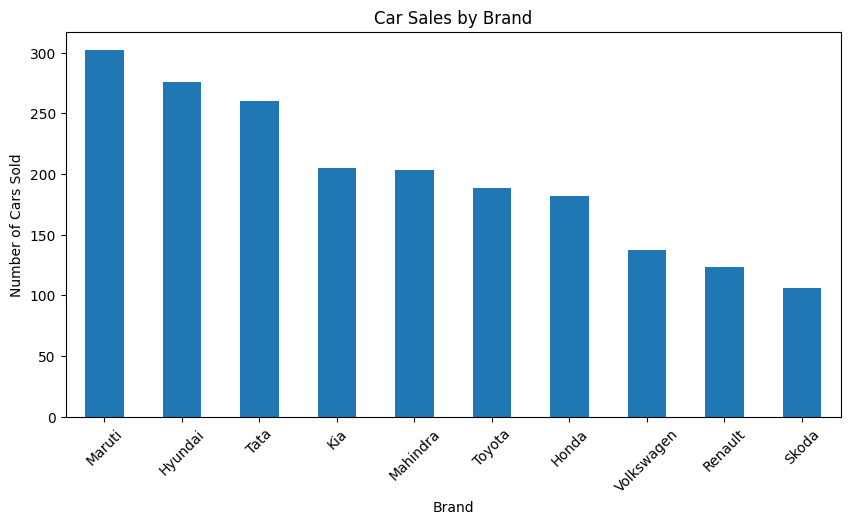

In [70]:
######### Brand wise sales  visualization ##########

brand_sales.plot(kind='bar', figsize=(10,5))

plt.title("Car Sales by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Cars Sold")
plt.xticks(rotation=45)
plt.show()

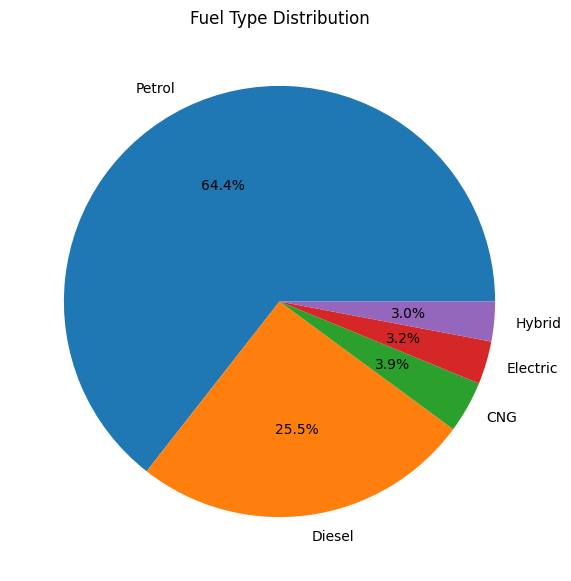

In [71]:
# Fuel Type Distribution Visualization

fuel_sales.plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))

plt.title("Fuel Type Distribution")
plt.ylabel("")
plt.show()

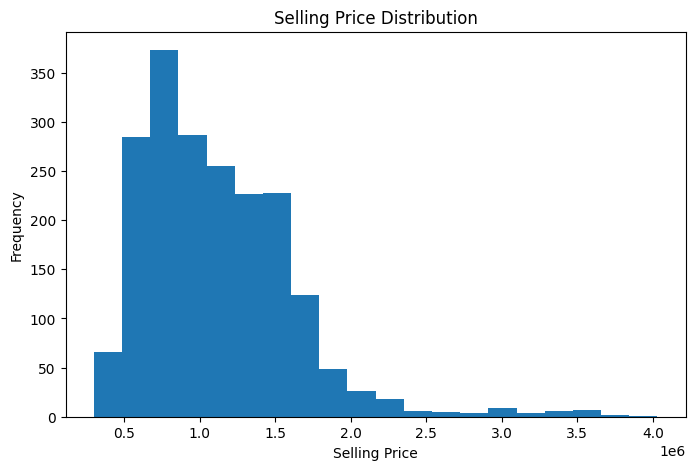

In [72]:
# Selling Price Distribution

plt.figure(figsize=(8,5))

plt.hist(df['Selling_Price'], bins=20)

plt.title("Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

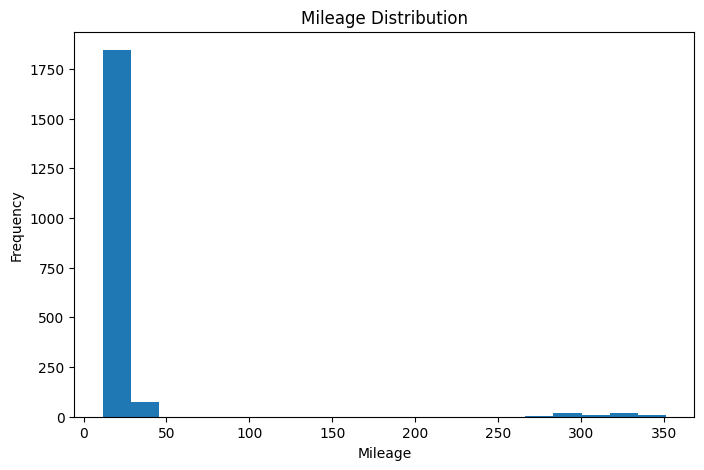

In [73]:
# Mileage Distribution

plt.figure(figsize=(8,5))

plt.hist(df['Mileage'], bins=20)

plt.title("Mileage Distribution")
plt.xlabel("Mileage")
plt.ylabel("Frequency")

plt.show()

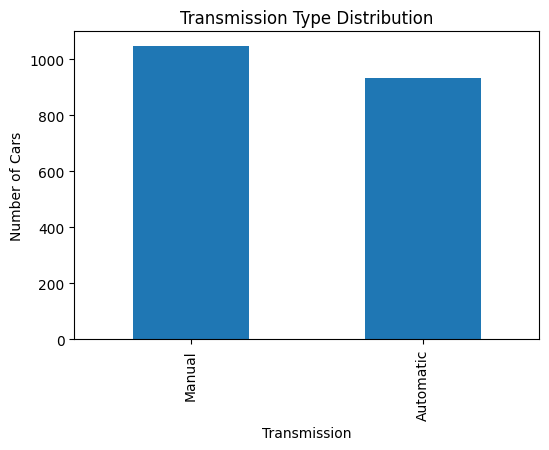

In [74]:
# Transmission Sales Visualization
transmission_sales.plot(kind='bar', figsize=(6,4))

plt.title("Transmission Type Distribution")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.show()

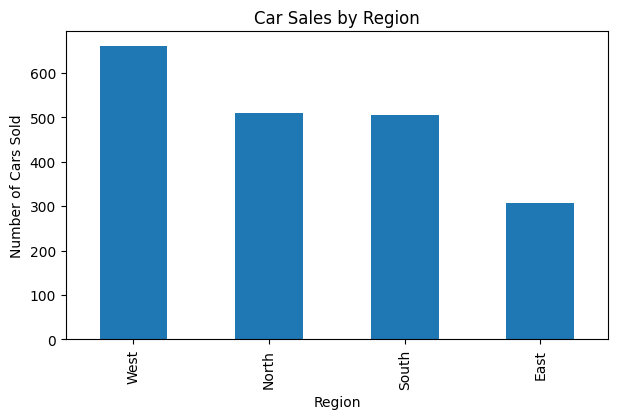

In [75]:
# Regional Sales Visualization

region_sales.plot(kind='bar', figsize=(7,4))

plt.title("Car Sales by Region")
plt.xlabel("Region")
plt.ylabel("Number of Cars Sold")

plt.show()

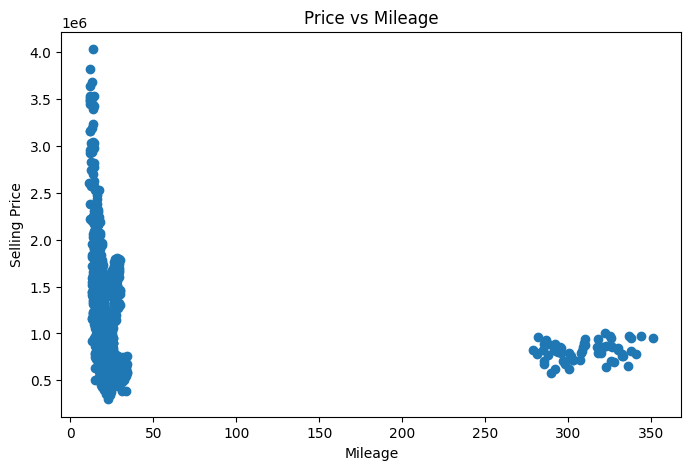

In [76]:
# Price vs Mileage Analysis

plt.figure(figsize=(8,5))

plt.scatter(df['Mileage'], df['Selling_Price'])

plt.title("Price vs Mileage")
plt.xlabel("Mileage")
plt.ylabel("Selling Price")

plt.show()

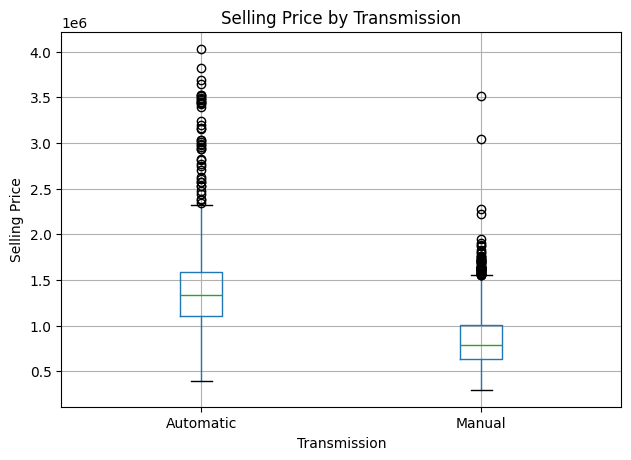

In [78]:
# Selling Price by Transmission


df.boxplot(column='Selling_Price', by='Transmission', figsize=(7,5))

plt.title("Selling Price by Transmission")
plt.suptitle("")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.show()

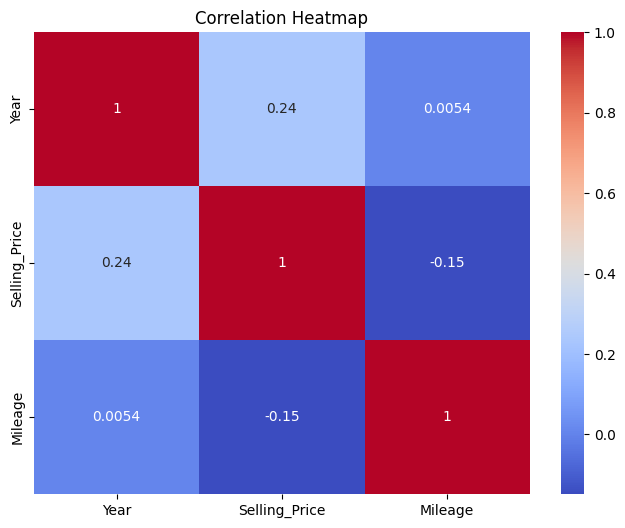

In [79]:
# Correlation Heatmap

plt.figure(figsize=(8,6))

sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [80]:
df.to_csv("cleaned_car_sales.csv", index=False)

In [81]:
import os
os.getcwd()

'C:\\Users\\Raj\\Epsilon\\DA_PROJECT'

In [83]:
df.to_csv("cleaned_car_sales.csv", index=False)